# Entity-structured processing and MAPPO reliability — results

Cooperative landmark coverage by five differential-drive robots. An episode succeeds only
if **every** robot reaches a distinct assigned landmark within 500 steps.

| Arm | Reward | Observation / network | Params | Role |
|---|---|---|---|---|
| **C** | 6-component | entity tokens → masked attention (actor **and** critic) | 566,917 | proposed |
| **B_wide** | 6-component | fixed index order → MLP, hidden 512 | **685,577** | capacity control (1.21× C) |
| **B** | 6-component | fixed index order → MLP | 207,131 | same-reward flat |
| **A** | legacy 9-component | legacy ego-centric, distance-sorted | 138,866 | contextual only |

**Primary endpoint: frozen held-out deterministic evaluation** — final checkpoint of each
run, 100 episodes from a common scenario bank (seeds 900000–900099) identical across every
arm, deterministic actions. Checkpoint selection was fixed before any evaluation numbers
existed and never informed by results.

The statistical unit is the **trained seed**. Evaluation episodes are repeated measures of a
single policy, never independent replicates.

⚠ Arm A is *contextual only* — not a reproduction of the published configuration, not a
reward ablation. A and B differ in reward **and** observation.

In [1]:
import json, re, os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.stats import mannwhitneyu

ROOT = os.environ.get("PPO_STUDY_ROOT", os.path.expanduser("~/dif_driven_ppo_study"))
ARMS = ["C", "B_wide", "B", "A"]
LABEL = {"C": "C  entity-structured", "B_wide": "B_wide  flat MLP (1.21x params)",
         "B": "B  flat MLP", "A": "A  legacy (contextual)"}
COL = {"C": "#2CA02C", "B_wide": "#DD8452", "B": "#4C72B0", "A": "#8C8C8C"}
PARAMS = {"C": 566917, "B_wide": 685577, "B": 207131, "A": 138866}

FIGDIR = f"{ROOT}/figures"
os.makedirs(FIGDIR, exist_ok=True)

def save(fig, name):
    # every figure is written to the shared figures directory as PDF and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{FIGDIR}/{name}.{ext}", dpi=200, bbox_inches="tight")
    print(f"saved {FIGDIR}/{name}.pdf (+png)")

ho = pd.read_csv(f"{ROOT}/heldout_eval.csv")
ho["arm"] = ho.run.str.rsplit("_n", n=1).str[0]
ho["seed"] = ho.run.str[-1].astype(int)
print(f"{len(ho)} checkpoints x {int(ho.episodes.iloc[0])} held-out episodes")

19 checkpoints x 100 held-out episodes


## Table 1 — held-out deterministic performance (PRIMARY)

In [2]:
cols = ["success_pct","coverage_pct","horizon_fail_pct",
        "completion_steps_success","path_len_all","path_len_success"]
T1 = ho.groupby("arm")[cols].mean().loc[ARMS].round(1)
T1.insert(0, "seeds", ho.groupby("arm").size().loc[ARMS])
T1["success_sd"] = ho.groupby("arm").success_pct.std(ddof=1).loc[ARMS].round(1)
T1["CV"] = (T1.success_sd / T1.success_pct).round(2)
T1["params"] = [PARAMS[a] for a in ARMS]
display(T1)
print("completion_steps_success: successes only; failures are right-censored at 500 steps "
      "and excluded.\npath_len is NOT censored (not a time-to-event variable); "
      "path_len_all is inflated by horizon failures, so only path_len_success is comparable.")

,seeds,success_pct,coverage_pct,horizon_fail_pct,completion_steps_success,path_len_all,path_len_success,success_sd,CV,params
arm,,,,,,,,,,
C,5,96.2,99.0,3.8,111.7,151.2,142.6,3.1,0.03,566917
B_wide,5,12.2,63.6,87.8,227.8,379.0,252.1,16.4,1.34,685577
B,5,7.4,69.3,92.6,212.3,516.4,245.4,5.0,0.68,207131
A,4,10.0,73.8,90.0,218.6,386.9,189.4,7.7,0.77,138866


completion_steps_success: successes only; failures are right-censored at 500 steps and excluded.
path_len is NOT censored (not a time-to-event variable); path_len_all is inflated by horizon failures, so only path_len_success is comparable.


## Table 2 — every seed

Mean ± SD is a poor summary for the flat arms (B_wide's SD exceeds its mean), so all raw
values are shown. **All prespecified seeds are reported, including contradictory ones.**

In [3]:
T2 = ho.pivot_table(index="arm", columns="seed", values="success_pct").loc[ARMS]
display(T2)
for a in ARMS:
    v = ho[ho.arm==a].success_pct.to_numpy()
    print(f"{a:8s} n={len(v)}  mean {v.mean():5.1f}  sd {v.std(ddof=1):5.1f}  "
          f"median {np.median(v):5.1f}  range [{v.min():.0f}, {v.max():.0f}]")

seed,1,2,3,4,5
arm,,,,,
C,93.0,93.0,98.0,97.0,100.0
B_wide,2.0,37.0,21.0,1.0,0.0
B,1.0,8.0,15.0,7.0,6.0
A,5.0,12.0,20.0,3.0,NaN


C        n=5  mean  96.2  sd   3.1  median  97.0  range [93, 100]
B_wide   n=5  mean  12.2  sd  16.4  median   2.0  range [0, 37]
B        n=5  mean   7.4  sd   5.0  median   7.0  range [1, 15]
A        n=4  mean  10.0  sd   7.7  median   8.5  range [3, 20]


## Table 3 — seed-level contrasts

Standard exact two-sided Mann–Whitney, with the nominal floor for the sample size.
Effect size and the raw seed values are the primary evidence; the p-value accompanies them
rather than replacing them. Failure to reject a difference is not evidence of equivalence.

In [4]:
def exact_mw(x, y):
    x, y = np.asarray(x,float), np.asarray(y,float); n1, n2 = len(x), len(y)
    test = mannwhitneyu(x, y, alternative="two-sided", method="exact")
    from math import comb
    return float(test.pvalue), 2/comb(n1+n2,n1), 2*float(test.statistic)/(n1*n2)-1

rows = []
for x, y in [("C","B_wide"),("C","B"),("C","A"),("B_wide","B"),("B_wide","A"),("B","A")]:
    vx = ho[ho.arm==x].success_pct.to_numpy(); vy = ho[ho.arm==y].success_pct.to_numpy()
    p, fl, rbc = exact_mw(vx, vy)
    rows.append(dict(contrast=f"{x} vs {y}", delta_pp=round(vx.mean()-vy.mean(),1),
                     p=round(p,4), p_floor=round(fl,4), rank_biserial=round(rbc,2),
                     separation="complete" if vx.min()>vy.max() or vy.min()>vx.max() else "overlapping"))
display(pd.DataFrame(rows))
print("No seed-level difference was detected among the flat configurations. With four "
      "or five training seeds, these tests have limited power and do not establish "
      "equivalence.")

,contrast,delta_pp,p,p_floor,rank_biserial,separation
0,C vs B_wide,84.0,0.0079,0.0079,1.00,complete
1,C vs B,88.8,0.0079,0.0079,1.00,complete
2,C vs A,86.2,0.0159,0.0159,1.00,complete
3,B_wide vs B,4.8,1.0000,0.0079,-0.08,overlapping
4,B_wide vs A,2.2,0.7302,0.0159,-0.20,overlapping
5,B vs A,-2.6,0.9048,0.0159,-0.10,overlapping


No seed-level difference was detected among the flat configurations. With four or five training seeds, these tests have limited power and do not establish equivalence.


### Figure 1 — held-out success and the capacity control

Left: every seed. Right: parameters against success — the capacity control sits to the
*right* of the proposed model (more parameters) and far below it.

saved <PPO_STUDY_ROOT>/figures/fig1_heldout_success_capacity.pdf (+png)


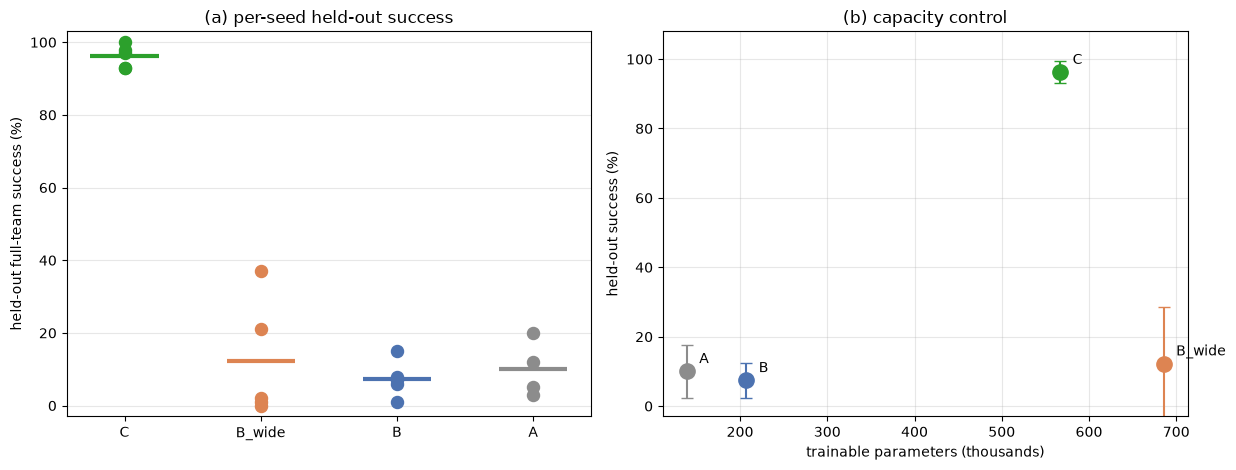

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
for i, a in enumerate(ARMS):
    v = ho[ho.arm==a].success_pct.to_numpy()
    ax1.scatter([i]*len(v), v, s=75, color=COL[a], zorder=3)
    ax1.hlines(v.mean(), i-.25, i+.25, color=COL[a], lw=3)
ax1.set_xticks(range(len(ARMS))); ax1.set_xticklabels(ARMS)
ax1.set_ylabel("held-out full-team success (%)"); ax1.set_ylim(-3,103)
ax1.set_title("(a) per-seed held-out success"); ax1.grid(alpha=.3, axis="y")
for a in ARMS:
    v = ho[ho.arm==a].success_pct
    ax2.errorbar(PARAMS[a]/1e3, v.mean(), yerr=v.std(ddof=1), fmt="o", ms=11,
                 color=COL[a], capsize=4)
    ax2.annotate(a, (PARAMS[a]/1e3, v.mean()), textcoords="offset points",
                 xytext=(9,6), fontsize=10)
ax2.set_xlabel("trainable parameters (thousands)"); ax2.set_ylabel("held-out success (%)")
ax2.set_title("(b) capacity control"); ax2.grid(alpha=.3); ax2.set_ylim(-3,108)
plt.tight_layout(); save(fig, "fig1_heldout_success_capacity"); plt.show()

### Figure 2 — partial versus full completion

The gap shows that partial coverage can look substantially better than the strict full-team
criterion. It does not by itself identify a terminal or one-agent-short mechanism.

saved <PPO_STUDY_ROOT>/figures/fig2_coverage_horizon.pdf (+png)


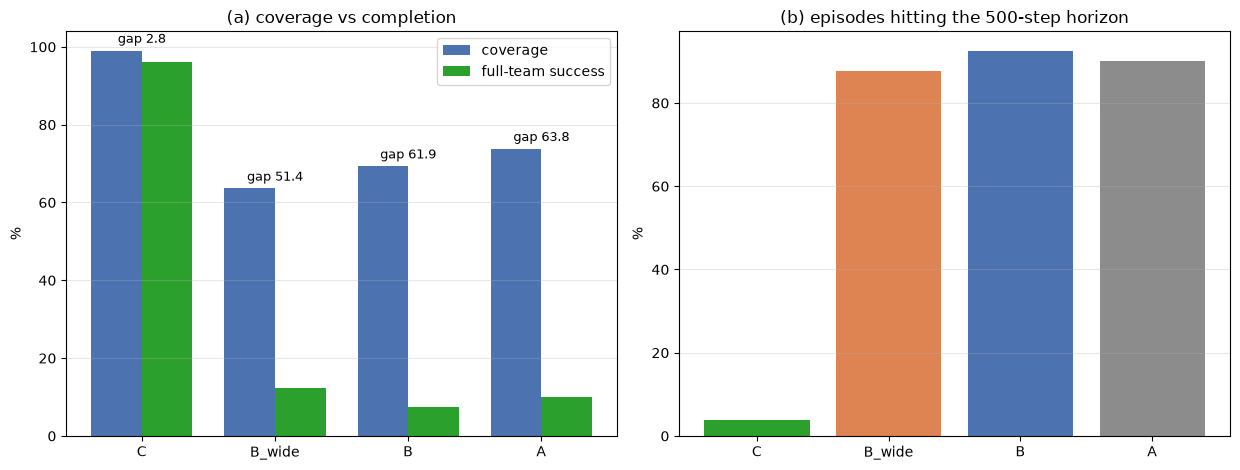

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
x = np.arange(len(ARMS)); w = .38
cov = [ho[ho.arm==a].coverage_pct.mean() for a in ARMS]
suc = [ho[ho.arm==a].success_pct.mean() for a in ARMS]
ax1.bar(x-w/2, cov, w, label="coverage", color="#4C72B0")
ax1.bar(x+w/2, suc, w, label="full-team success", color="#2CA02C")
for i,(c,s) in enumerate(zip(cov,suc)):
    ax1.annotate(f"gap {c-s:.1f}", (i, max(c,s)+2), ha="center", fontsize=9)
ax1.set_xticks(x); ax1.set_xticklabels(ARMS); ax1.legend(); ax1.grid(alpha=.3, axis="y")
ax1.set_title("(a) coverage vs completion"); ax1.set_ylabel("%")
hf = [ho[ho.arm==a].horizon_fail_pct.mean() for a in ARMS]
ax2.bar(ARMS, hf, color=[COL[a] for a in ARMS])
ax2.set_title("(b) episodes hitting the 500-step horizon"); ax2.set_ylabel("%")
ax2.grid(alpha=.3, axis="y")
plt.tight_layout(); save(fig, "fig2_coverage_horizon"); plt.show()

### Figure 3 — reliability

Coefficient of variation across seeds. The proposed configuration is two orders of
magnitude more consistent than the capacity control, whose SD exceeds its mean.

saved <PPO_STUDY_ROOT>/figures/fig3_reliability_cv.pdf (+png)


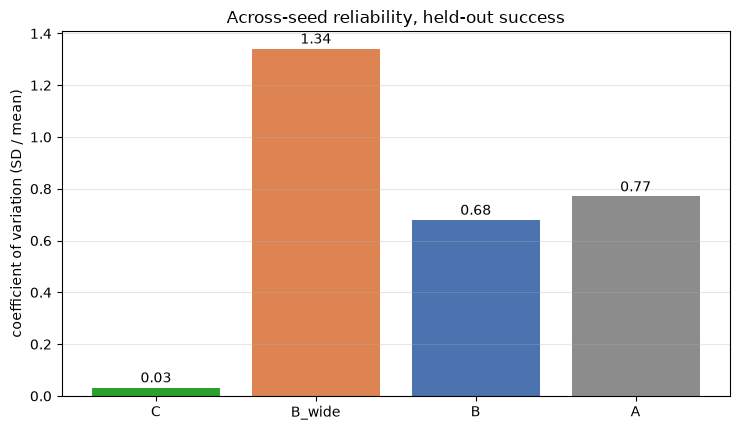

In [7]:
fig, ax = plt.subplots(figsize=(7.5,4.4))
cv = [ho[ho.arm==a].success_pct.std(ddof=1)/ho[ho.arm==a].success_pct.mean() for a in ARMS]
ax.bar(ARMS, cv, color=[COL[a] for a in ARMS])
for i,(a,c) in enumerate(zip(ARMS,cv)):
    ax.annotate(f"{c:.2f}", (i,c+.02), ha="center", fontsize=10)
ax.set_ylabel("coefficient of variation (SD / mean)")
ax.set_title("Across-seed reliability, held-out success"); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); save(fig, "fig3_reliability_cv"); plt.show()

### Figure 4 — matched deterministic rollouts

Both policies evaluated from the **same** scenario seed (900000, the first in the
evaluation bank — a declared rule, not a search for a favourable example). Illustrative
only; it shows what each policy does on one scenario, not why one outperforms the other.

In [8]:
p = f"{ROOT}/figures/fig_matched_C_vs_Bwide.png"
if os.path.exists(p):
    fig, ax = plt.subplots(figsize=(14,7)); ax.imshow(mpimg.imread(p)); ax.axis("off"); plt.show()
else:
    print("run tools/matched_trajectories.py first")

run tools/matched_trajectories.py first


### Table 4 / Figure 5 — zero-shot cardinality (secondary)

The n=5-trained entity-structured policy evaluated at other team sizes **without
retraining**. The fixed-index arms cannot be evaluated this way at all: their observation
dimension is a function of the team size. This is a capability demonstration over the
tested range, not a claim of general cardinality generalisation.

eval_n,4,5,6
seed,,,
1,93.0,92.0,88.0
2,95.0,91.0,92.0
3,100.0,98.0,98.0
4,97.0,97.0,98.0
5,99.0,100.0,99.0


success      coverage      horizon_fail     
          mean  std     mean  std         mean  std
eval_n                                             
4         96.8  2.9     99.0  1.1          3.2  2.9
5         95.6  3.9     99.0  0.9          4.4  3.9
6         95.0  4.8     98.9  1.2          5.0  4.8

saved <PPO_STUDY_ROOT>/figures/fig5_zeroshot_cardinality.pdf (+png)


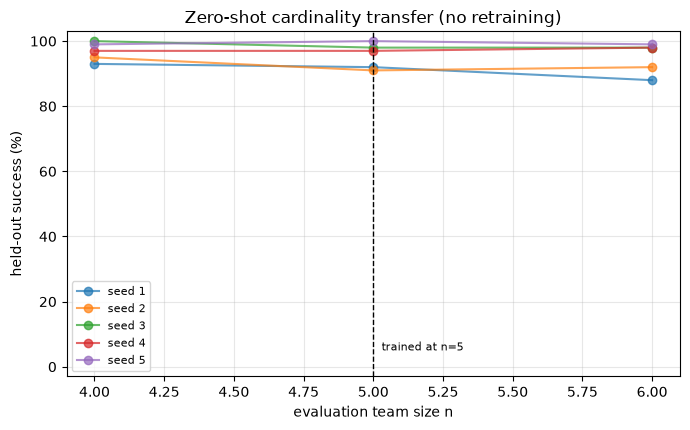

In [9]:
zp = next((p for p in ["res/zeroshot_cardinality_reproduced.csv",
                              "zeroshot_cardinality_reproduced.csv"]
           if os.path.exists(p)), None)
if zp is not None:
    zs = pd.read_csv(zp)
    display(zs.pivot_table(index="seed", columns="eval_n", values="success").round(1))
    g = zs.groupby("eval_n")[["success","coverage","horizon_fail"]].agg(["mean","std"]).round(1)
    display(g)
    fig, ax = plt.subplots(figsize=(7,4.4))
    for s in sorted(zs.seed.unique()):
        d = zs[zs.seed==s].sort_values("eval_n")
        ax.plot(d.eval_n, d.success, "o-", alpha=.7, label=f"seed {s}")
    ax.axvline(5, ls="--", c="k", lw=1); ax.text(5.03, 5, "trained at n=5", fontsize=8)
    ax.set_xlabel("evaluation team size n"); ax.set_ylabel("held-out success (%)")
    ax.set_ylim(-3,103); ax.grid(alpha=.3); ax.legend(fontsize=8)
    ax.set_title("Zero-shot cardinality transfer (no retraining)")
    plt.tight_layout(); save(fig, "fig5_zeroshot_cardinality"); plt.show()
else:
    print("zero-shot evaluation not run")

## Secondary — training diagnostics

Training-window statistics are **not** the endpoint. Shown for completeness and to record
that deterministic evaluation *widened* the gap: C lost 1.5 pp moving from training window
to held-out, the flat arms 4.6–6.6 pp.

The logged per-episode "score" is deliberately **not** plotted: it is an unweighted mean of
reward components and is incomparable across arms (A has 9 components, the others 6).

saved <PPO_STUDY_ROOT>/figures/fig6_training_transitions.pdf (+png)


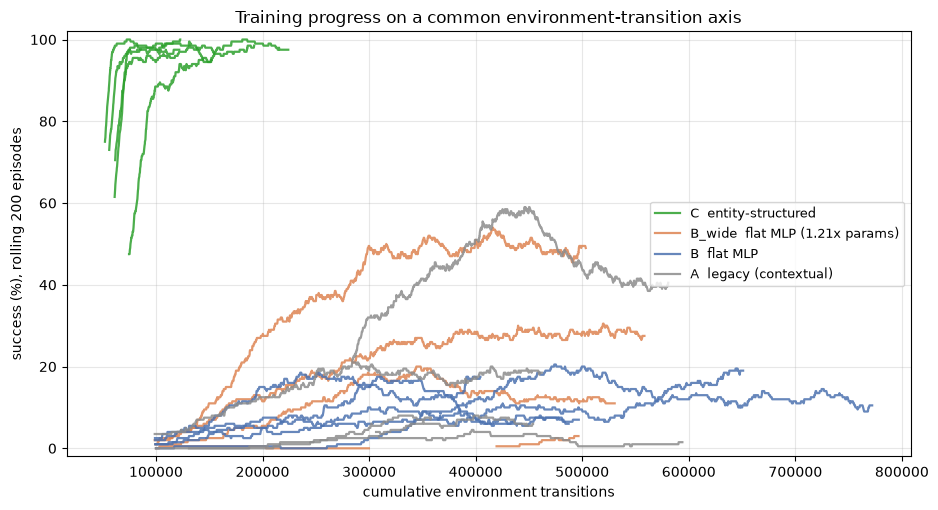

In [10]:
pat = re.compile(r"^\[MAPPO\] ep (\d+) score \S+ done (\d+)/(\d+) steps (\d+)")
def load(arm, seed):
    f = f"{ROOT}/logs/{arm}_n5_seed{seed}.log"
    if not os.path.exists(f): return None
    r = []
    for line in open(f):
        m = pat.match(line)
        if m: g = m.groups(); r.append((int(g[0]), int(g[1]), int(g[2]), int(g[3])))
    if not r: return None
    d = {x[0]: x for x in r}; r = [d[k] for k in sorted(d)]
    return np.array([x[1] for x in r]), r[0][2], np.array([x[3] for x in r])

W = 200
fig, ax = plt.subplots(figsize=(9.5,5.2))
for a in ARMS:
    first = True
    for s in (1,2,3,4,5):
        v = load(a,s)
        if v is None: continue
        done, N, steps = v
        if len(done) < W: continue
        roll = np.convolve((done==N).astype(float), np.ones(W)/W, "valid")*100
        ax.plot(steps[W-1:][:len(roll)], roll, color=COL[a], lw=1.6, alpha=.85,
                label=LABEL[a] if first else None); first = False
ax.set_xlabel("cumulative environment transitions"); ax.set_ylabel(f"success (%), rolling {W} episodes")
ax.set_title("Training progress on a common environment-transition axis")
ax.set_ylim(-2,102); ax.grid(alpha=.3); ax.legend(fontsize=9, loc="center right")
plt.tight_layout(); save(fig, "fig6_training_transitions"); plt.show()

## Summary

- **C reaches 96.2 ± 3.1 % held-out deterministic full-team success**; the three flat-MLP
  arms reach 7.4–12.2 %. No difference was detected among those flat arms, but the small
  seed samples do not establish equivalence.
- **Complete seed-level separation** in every contrast with C (p = 0.0079 for the two 5v5
  primary contrasts; rank-biserial +1.00).
- **The tested capacity increase did not close the gap**: B_wide carries 1.21× C's
  parameters and shows no detectable advantage over B, while exhibiting greater observed
  dispersion.
- **Partial coverage overstates strict completion**: coverage − success is 2.8 pp for C
  against 51–64 pp for the flat arms; this descriptive gap does not establish a terminal
  mechanism.
- **Reliability**: CV 0.03 for C against 0.68–1.34.

**Limitations.** One environment, one training team size, five seeds. No mechanism is
established — we show *that* the configuration is reliable here, not *why*. The comparison
isolates the complete entity-structured configuration (actor, critic and masking of
completed entities together), not attention alone. Path length is comparable only among
successful episodes. Execution uses global scene information and is not decentralised.